# 04 · Segmentação de estruturas retinianas

**Ementa 04** · Segmentar é separar a imagem em regiões com significado. Na retina, três famílias de estruturas interessam:

| Estrutura | Por que importa | Neste notebook |
|---|---|---|
| **Árvore vascular** | calibre e tortuosidade dos vasos; retinopatia diabética e hipertensão | Frangi/Sato/black-hat, avaliação **quantitativa** contra o padrão-ouro do HRF |
| **Disco óptico** | ponto de referência (a "régua" do notebook 01); base da razão escavação/disco do glaucoma | localização e segmentação grosseira |
| **Lesões** (exsudatos, drusas, hemorragias) | sinais de RD e DMRI | candidatos por morfologia — e por que **não bastam** |

Método clássico ≠ inferior: ele é rápido, explicável e não precisa de dados rotulados — mas tem limites claros, que vamos medir. Isso justifica o **aprendizado profundo do Módulo 4**.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from retina_pdi import dados, pipeline as P, visualizacao as V

V.configurar_estilo()
print(f"OpenCV {cv2.__version__} | NumPy {np.__version__} | pandas {pd.__version__}")
import time
from skimage import filters
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, average_precision_score
from retina_pdi import metricas as M

OpenCV 4.14.0 | NumPy 2.5.3 | pandas 3.0.6


In [2]:
hrf = dados.carregar_hrf(1168)                                    # 45 imagens HRF a 1168 px + padrão-ouro de vasos e FOV oficial
por_id = {it["meta"].id: it for it in hrf}
ref = por_id["hrf_01_h"]                                          # saudável: vamos construir o método nela
rgb, fov, gt = ref["rgb"], ref["fov"], ref["vasos"]
fe = P.erodir_fov(fov, max(3, int(0.01 * min(fov.shape))))
print(f"{len(hrf)} imagens · imagem de trabalho {rgb.shape[1]}×{rgb.shape[0]} · vasos = {100*gt[fov].mean():.1f}% do FOV")

45 imagens · imagem de trabalho 1168×779 · vasos = 12.1% do FOV


## 1. Vasos passo a passo

**Ideia:** no canal verde os vasos são **cristas escuras e finas** sobre um fundo mais claro e suave. O pipeline:
`canal verde → tapar a moldura → corrigir iluminação → filtro de crista (vesselness) → limiar → limpeza`.

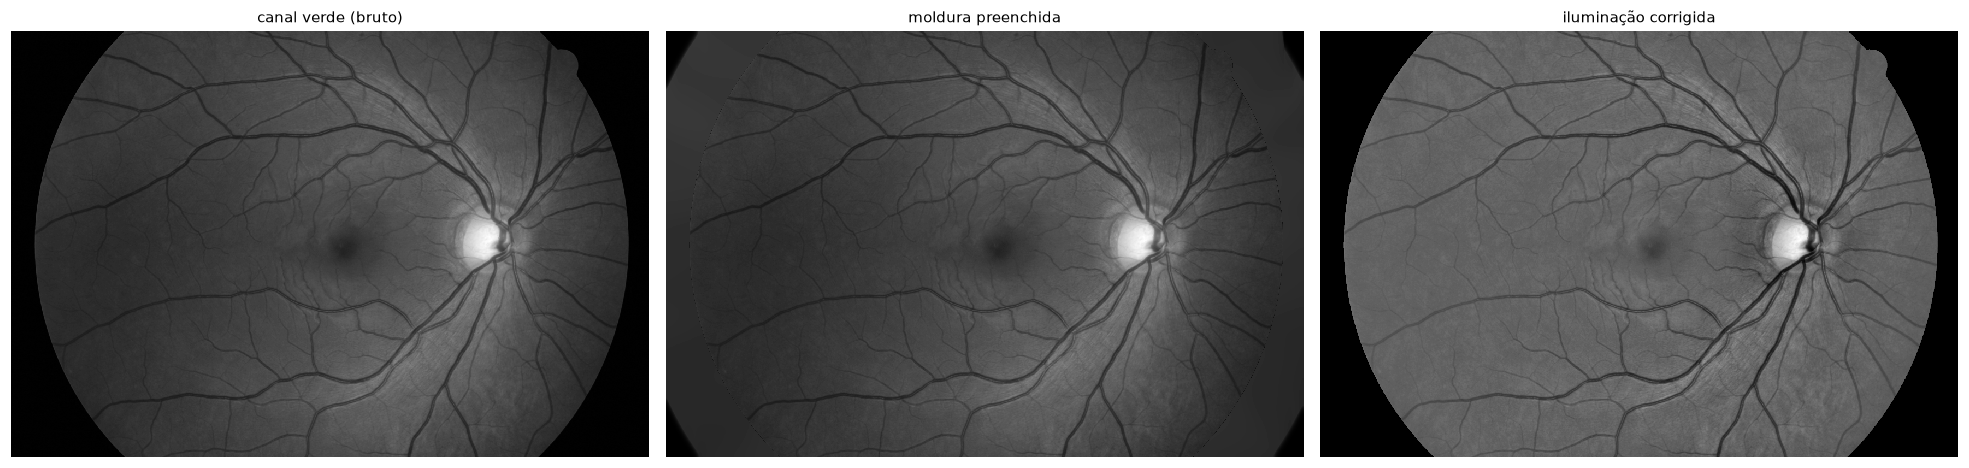

In [3]:
verde = rgb[..., 1]
g1 = P.preencher_fora_do_fov(verde, fov)          # moldura preta → média local (evita um "vaso" falso ao longo da borda do círculo)
g2 = P.corrigir_iluminacao(g1, fov, 0.05)         # remove o gradiente lento de brilho
V.grade([verde, g1, g2], ["canal verde (bruto)", "moldura preenchida", "iluminação corrigida"], colunas=3, largura=6)
plt.show()

### 1.1 Três "detectores de vaso"
* **Black-hat morfológico**: `fechamento(I) − I` — realça estruturas *escuras menores que o elemento estruturante*.
* **Sato** e **Frangi**: autovalores da matriz **Hessiana** em várias escalas σ. Um vaso é uma crista: um autovalor grande (curvatura *através* do vaso) e outro ≈ 0 (*ao longo* dele). Frangi ainda penaliza formas em "bolha".

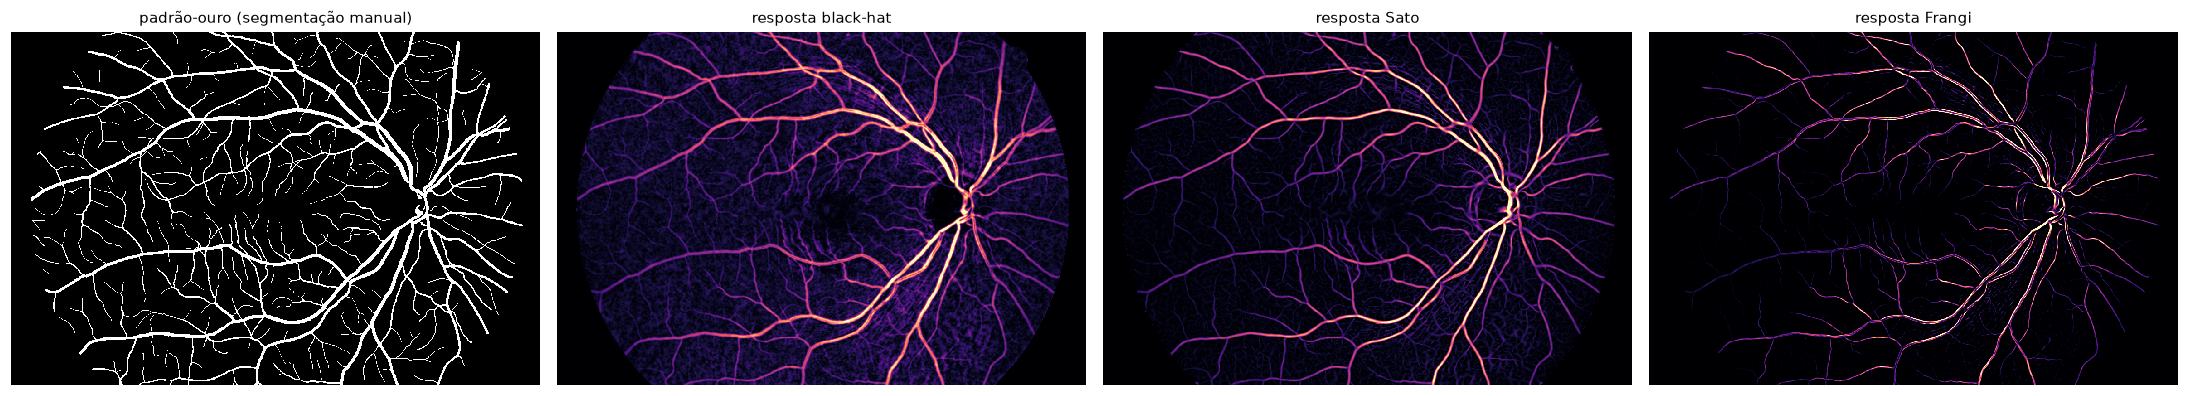

In [4]:
def resp_blackhat(g, f_):
    r = max(5, int(0.012 * min(g.shape)))
    c = P.clahe(g, 2.0, (8, 8))
    bh = cv2.morphologyEx(c, cv2.MORPH_BLACKHAT, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * r + 1, 2 * r + 1)))
    return cv2.GaussianBlur(bh, (0, 0), 1.0).astype(np.float32)

SIGMAS = (1.5, 2.5, 3.5)
def resp_sato(g, f_):    return filters.sato(P.corrigir_iluminacao(g, f_, 0.05).astype(np.float32) / 255, sigmas=SIGMAS, black_ridges=True).astype(np.float32)
def resp_frangi(g, f_):  return filters.frangi(P.corrigir_iluminacao(g, f_, 0.05).astype(np.float32) / 255, sigmas=SIGMAS, black_ridges=True, beta=0.5, gamma=None).astype(np.float32)

respostas = {"black-hat": resp_blackhat(g1, fov), "Sato": resp_sato(g1, fov), "Frangi": resp_frangi(g1, fov)}
fig, axs = plt.subplots(1, 4, figsize=(20, 3.6))
axs[0].imshow(gt, cmap="gray"); axs[0].set_title("padrão-ouro (segmentação manual)")
for ax, (n, r) in zip(axs[1:], respostas.items()):
    ax.imshow(np.where(fov, r, 0), cmap="magma", vmax=np.percentile(r[fe], 99.5)); ax.set_title(f"resposta {n}")
for a in axs: a.axis("off")
fig.tight_layout(); V.salvar_figura(fig, "04_respostas_vasos"); plt.show()

### 1.2 Binarizar: o limiar decide tudo
A resposta é contínua; precisamos decidir "vaso ou não". Três estratégias sobre a resposta de Frangi:

1. **Otsu** — limiar que separa duas classes de tamanho comparável (aqui os vasos são só ≈ 9 % dos pixels do FOV!);
2. **percentil** — assume uma fração de vasos (p. ex. os 12 % mais altos);
3. **histerese** — dois limiares: aceita pixels acima do alto **e** os acima do baixo *conectados* a eles (vasos contínuos, menos pontos soltos).

In [5]:
resp = respostas["Frangi"]
v = resp[fe]
b_otsu = (resp > filters.threshold_otsu(v)) & fe
b_pct = (resp > np.percentile(v, 88)) & fe
b_hist = filters.apply_hysteresis_threshold(resp, np.percentile(v, 88), np.percentile(v, 95)) & fe
b_final = P.remover_componentes_pequenos(b_hist, int(3e-4 * b_hist.size))

candidatas = {"Otsu": b_otsu, "top 12 % (percentil)": b_pct, "histerese 88/95": b_hist, "histerese + limpeza": b_final}
linhas = [dict(binarização=n, **P.metricas_segmentacao(b, gt, fov)) for n, b in candidatas.items()]
print("o histograma da resposta é muito assimétrico → o limiar de Otsu cai alto demais:", f"Otsu = percentil {100 * (v < filters.threshold_otsu(v)).mean():.1f}")
pd.DataFrame(linhas).set_index("binarização").round(3)

o histograma da resposta é muito assimétrico → o limiar de Otsu cai alto demais: Otsu = percentil 96.3


,sensibilidade,especificidade,acuracia,precisao,dice,iou
binarização,,,,,,
Otsu,0.295,0.999,0.914,0.967,0.452,0.292
top 12 % (percentil),0.742,0.967,0.940,0.758,0.750,0.600
histerese 88/95,0.696,0.984,0.949,0.856,0.768,0.623
histerese + limpeza,0.681,0.988,0.951,0.887,0.770,0.626


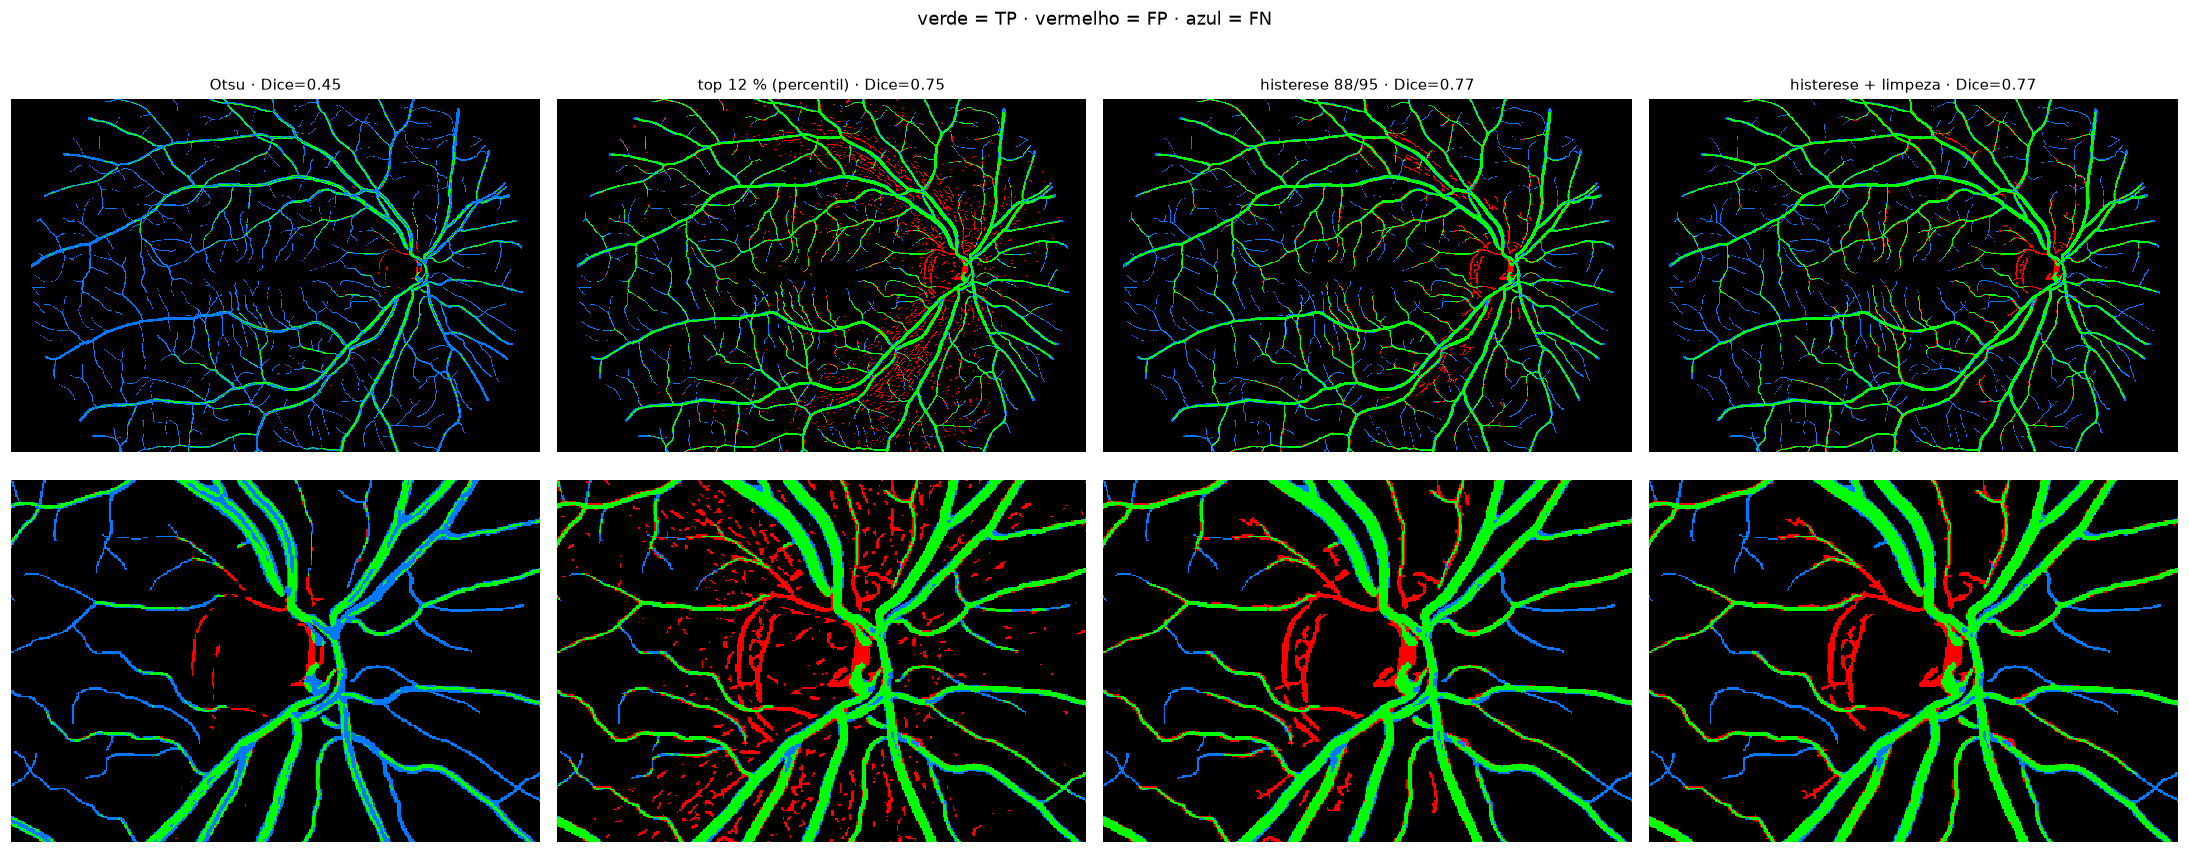

In [6]:
def comparacao(pred, gt_, fov_):
    """Sobreposição: verde = acerto (TP), vermelho = falso positivo (FP), azul = vaso não encontrado (FN)."""
    out = np.zeros(pred.shape + (3,), np.uint8)
    out[pred & gt_] = (0, 255, 0); out[pred & ~gt_] = (255, 0, 0); out[~pred & gt_] = (0, 120, 255)
    out[~fov_] = 0
    return out

disco = P.localizar_disco_optico(rgb, fov)
cy, cx = (int(x) for x in disco.centro)
zoom = (slice(max(cy - 130, 0), cy + 130), slice(max(cx - 190, 0), cx + 190))
fig, axs = plt.subplots(2, 4, figsize=(20, 8))
for j, (n, b) in enumerate(candidatas.items()):
    axs[0, j].imshow(comparacao(b, gt, fov)); axs[0, j].set_title(f"{n} · Dice={P.metricas_segmentacao(b, gt, fov)['dice']:.2f}")
    axs[1, j].imshow(comparacao(b, gt, fov)[zoom])
    axs[0, j].axis("off"); axs[1, j].axis("off")
fig.suptitle("verde = TP · vermelho = FP · azul = FN", y=1.0)
fig.tight_layout(); V.salvar_figura(fig, "04_binarizacao_vasos"); plt.show()

**Otsu falha aqui** porque assume duas classes de pesos comparáveis; a **histerese** recupera vasos contínuos com poucos falsos positivos, e a **limpeza** remove pontos isolados.
O erro típico está nos **vasos mais finos** (azul: não encontrados) e nos **falsos positivos** de bordas e do reflexo em volta do disco.

## 2. Avaliação quantitativa nas 45 imagens do HRF

Métricas por pixel **dentro do FOV**: *sensibilidade* (fração dos pixels de vaso encontrada), *especificidade* (fração do fundo corretamente rejeitada), *Dice* (equilíbrio entre acertos e erros — a métrica principal, porque a classe "vaso" é rara e a acurácia engana: dizer "nunca é vaso" já dá ≈ 91 %).
*(Leva ~ 1–2 minutos.)*

In [7]:
def limpo(b, area_rel=3e-4): return P.remover_componentes_pequenos(b, int(area_rel * b.size))

registros, tempos = [], {"black-hat": [], "Sato": [], "Frangi (percentil)": [], "Frangi (histerese)": []}
for it in hrf:
    r_, f_, g_ = it["rgb"], it["fov"], it["vasos"]
    fe_ = P.erodir_fov(f_, max(3, int(0.01 * min(f_.shape))))
    gv = P.preencher_fora_do_fov(r_[..., 1], f_)
    saidas = {}
    t0 = time.perf_counter(); rb = resp_blackhat(gv, f_); saidas["black-hat"] = limpo((rb > np.percentile(rb[fe_], 88)) & fe_); tempos["black-hat"].append(time.perf_counter() - t0)
    t0 = time.perf_counter(); rs = resp_sato(gv, f_); saidas["Sato"] = limpo((rs > np.percentile(rs[fe_], 88)) & fe_); tempos["Sato"].append(time.perf_counter() - t0)
    t0 = time.perf_counter(); rf = resp_frangi(gv, f_); saidas["Frangi (percentil)"] = limpo((rf > np.percentile(rf[fe_], 88)) & fe_); tempos["Frangi (percentil)"].append(time.perf_counter() - t0)
    t0 = time.perf_counter(); saidas["Frangi (histerese)"] = P.segmentar_vasos(r_, f_); tempos["Frangi (histerese)"].append(time.perf_counter() - t0)
    for n, b in saidas.items():
        registros.append(dict(imagem=it["meta"].id, condicao=it["meta"].condicao, método=n, **P.metricas_segmentacao(b, g_, f_)))
avaliacao = pd.DataFrame(registros)
resumo = avaliacao.groupby("método")[["dice", "sensibilidade", "especificidade", "acuracia"]].mean()
resumo["s/imagem"] = pd.Series({k: np.mean(v) for k, v in tempos.items()})
resumo.sort_values("dice", ascending=False).round(3)

,dice,sensibilidade,especificidade,acuracia,s/imagem
método,,,,,
Frangi (percentil),0.748,0.739,0.978,0.956,0.446
Frangi (histerese),0.748,0.734,0.979,0.956,0.518
Sato,0.705,0.773,0.960,0.943,0.311
black-hat,0.682,0.731,0.961,0.939,0.013


condicao,glaucoma,normal,rd
método,,,
Frangi (histerese),0.750,0.794,0.699
Frangi (percentil),0.750,0.796,0.699
Sato,0.686,0.763,0.666
black-hat,0.669,0.735,0.642


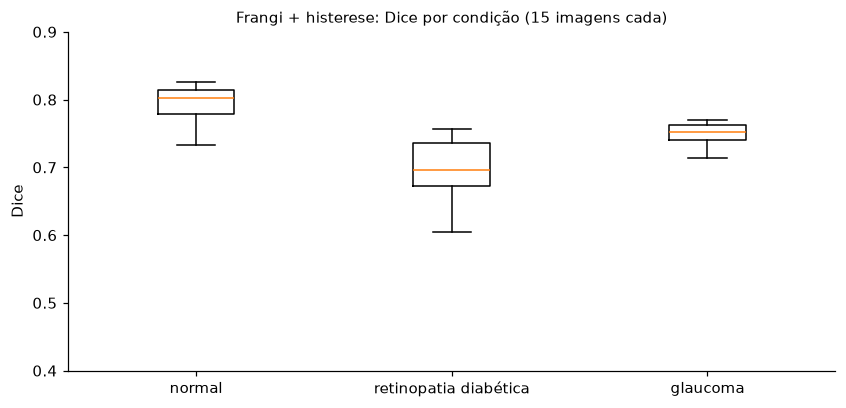

In [8]:
por_cond = avaliacao.pivot_table(index="método", columns="condicao", values="dice", aggfunc="mean").round(3)
display(por_cond)
fig, ax = plt.subplots(figsize=(9, 4))
sel = avaliacao[avaliacao["método"] == "Frangi (histerese)"]
ax.boxplot([sel[sel.condicao == c].dice for c in ["normal", "rd", "glaucoma"]], showfliers=True)
ax.set_xticklabels(["normal", "retinopatia diabética", "glaucoma"]); ax.set_ylabel("Dice"); ax.set_ylim(0.4, 0.9)
ax.set_title("Frangi + histerese: Dice por condição (15 imagens cada)")
plt.show()

* **Frangi** (Dice médio ≈ 0,75) > **Sato** (≈ 0,71) > **black-hat** (≈ 0,68). Percentil e histerese empatam no Dice médio; a histerese exige conectividade e tende a deixar menos pontos soltos (na imagem de trabalho, a precisão sobe de 0,76 para 0,89 com histerese + limpeza).
* Custo: o **black-hat** é ~ 40× mais rápido que o Frangi neste computador (≈ 0,01 s × 0,5 s por imagem) — uma opção para hardware limitado, ao custo de ≈ 0,07 de Dice.
* O Dice **cai na retinopatia diabética** (≈ 0,70 contra ≈ 0,79 nos normais): as lesões (exsudatos brilhantes, hemorragias escuras) e a textura irregular produzem falsos positivos e mascaram vasos finos. É exatamente o caso clínico que mais interessa — o desempenho medido em imagens saudáveis não se transfere automaticamente.
* Métodos supervisionados (redes U-Net) costumam reportar Dice da ordem de 0,8 no HRF, ao custo de dados rotulados e processamento — consulte a literatura para valores exatos.

## 3. Curvas ROC e Precisão–Revocação

O Dice avalia **um** limiar. As curvas mostram o desempenho em **todos** os limiares. Usamos os escores de pixels de 10 imagens (amostrando 1 em cada 6 pixels do FOV) e comparamos com uma linha de base sem filtro de crista (canal verde invertido):

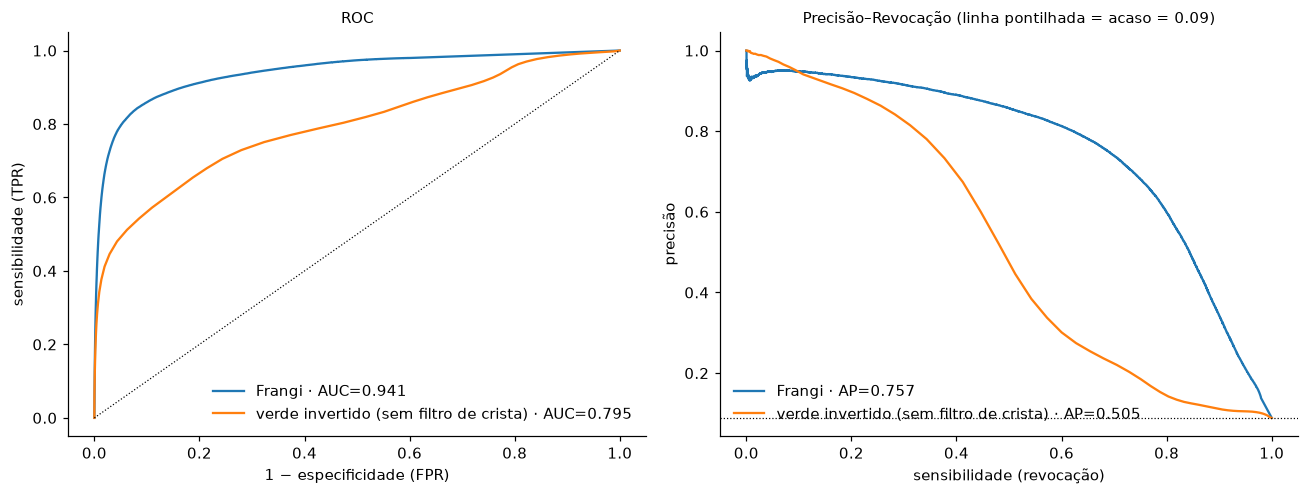

In [9]:
rng = np.random.default_rng(0)
escores_f, escores_g, rotulos = [], [], []
for it in hrf[::4][:10]:
    r_, f_, g_ = it["rgb"], it["fov"], it["vasos"]
    fe_ = P.erodir_fov(f_, max(3, int(0.01 * min(f_.shape))))
    gv = P.preencher_fora_do_fov(r_[..., 1], f_)
    fr = resp_frangi(gv, f_); inv = 255 - P.corrigir_iluminacao(gv, f_, 0.05).astype(np.float32)
    idx = np.flatnonzero(fe_.ravel())[::6]
    escores_f.append(fr.ravel()[idx]); escores_g.append(inv.ravel()[idx]); rotulos.append(g_.ravel()[idx])
escores_f, escores_g, rotulos = map(np.concatenate, (escores_f, escores_g, rotulos))

fig, axs = plt.subplots(1, 2, figsize=(12, 4.6))
for nome, e in [("Frangi", escores_f), ("verde invertido (sem filtro de crista)", escores_g)]:
    fpr, tpr, _ = roc_curve(rotulos, e); axs[0].plot(fpr, tpr, label=f"{nome} · AUC={roc_auc_score(rotulos, e):.3f}")
    pr, rc, _ = precision_recall_curve(rotulos, e); axs[1].plot(rc, pr, label=f"{nome} · AP={average_precision_score(rotulos, e):.3f}")
axs[0].plot([0, 1], [0, 1], "k:", lw=0.8); axs[0].set_xlabel("1 − especificidade (FPR)"); axs[0].set_ylabel("sensibilidade (TPR)"); axs[0].set_title("ROC"); axs[0].legend(frameon=False)
axs[1].axhline(rotulos.mean(), color="k", ls=":", lw=0.8); axs[1].set_xlabel("sensibilidade (revocação)"); axs[1].set_ylabel("precisão"); axs[1].set_title(f"Precisão–Revocação (linha pontilhada = acaso = {rotulos.mean():.2f})"); axs[1].legend(frameon=False)
fig.tight_layout(); V.salvar_figura(fig, "04_roc_pr_vasos"); plt.show()

Com apenas ≈ 9 % de pixels positivos, a **ROC parece ótima** mesmo para métodos medíocres (a especificidade é "fácil"); a curva **Precisão–Revocação** é mais honesta em classes raras.
A distância entre o Frangi e a linha de base mostra o valor do filtro de crista sobre a simples intensidade.

## 4. Resolução de trabalho × desempenho × tempo

As escalas do Frangi (σ) são medidas em **pixels**: se a imagem tem metade da largura, os vasos também têm metade da espessura, e σ deve acompanhar. Rodamos o método com σ **proporcional à largura** em seis tamanhos, em 6 imagens (2 por condição):

In [10]:
registros = []
for larg in [292, 438, 584, 876, 1168, 1752]:
    itens = [it for c in ("normal", "rd", "glaucoma") for it in dados.carregar_hrf(larg, condicao=c, n=2)]
    esc = larg / 1168
    for it in itens:
        f_ = P.mascara_fov(it["rgb"])
        t0 = time.perf_counter(); pred = P.segmentar_vasos(it["rgb"], f_, sigmas=tuple(s * esc for s in (1.5, 2.5, 3.5))); dt = time.perf_counter() - t0
        registros.append(dict(largura=larg, dice=P.metricas_segmentacao(pred, it["vasos"], f_)["dice"], segundos=dt))
res_res = pd.DataFrame(registros).groupby("largura").mean().round(3)
res_res

,dice,segundos
largura,,
292,0.339,0.069
438,0.732,0.142
584,0.744,0.176
876,0.741,0.252
1168,0.743,0.516
1752,0.744,1.290


Leia a tabela: o Dice fica **praticamente estável** de ≈ 584 a 1752 px (com σ proporcional), enquanto o tempo cresce aproximadamente com o quadrado da largura — mais pixels não trazem mais precisão para os vasos *deste método*.
Abaixo de certo tamanho os vasos finos deixam de ser resolvidos e o Dice desaba (aqui, de ≈ 0,73 em 438 px para ≈ 0,34 em 292 px). A regra prática: **trabalhe na menor resolução que preserva o vaso mais fino**. No **Raspberry Pi 5** isso pode decidir se a segmentação de vasos roda em tempo útil (Frente F2) — **meça no dispositivo**; os tempos acima são deste computador.

## 5. Disco óptico

`P.localizar_disco_optico` usa quatro ideias: **(1)** o disco é a região mais clara; **(2)** um *fechamento morfológico* apaga os vasos escuros que o cortam; **(3)** Otsu numa janela em torno do máximo suavizado; **(4)** uma **checagem de plausibilidade**: se o raio passa de ≈ 8,5 % do diâmetro do FOV, o disco "vazou" para o halo claro ao redor e o limiar é refeito só entre os pixels mais claros (sem esse passo, metade dos normais do RFMiD saía com raio o dobro do correto — um exemplo de como **validar contra a anatomia** conserta um método). Testamos em 4 imagens de cada condição (fontes misturadas):

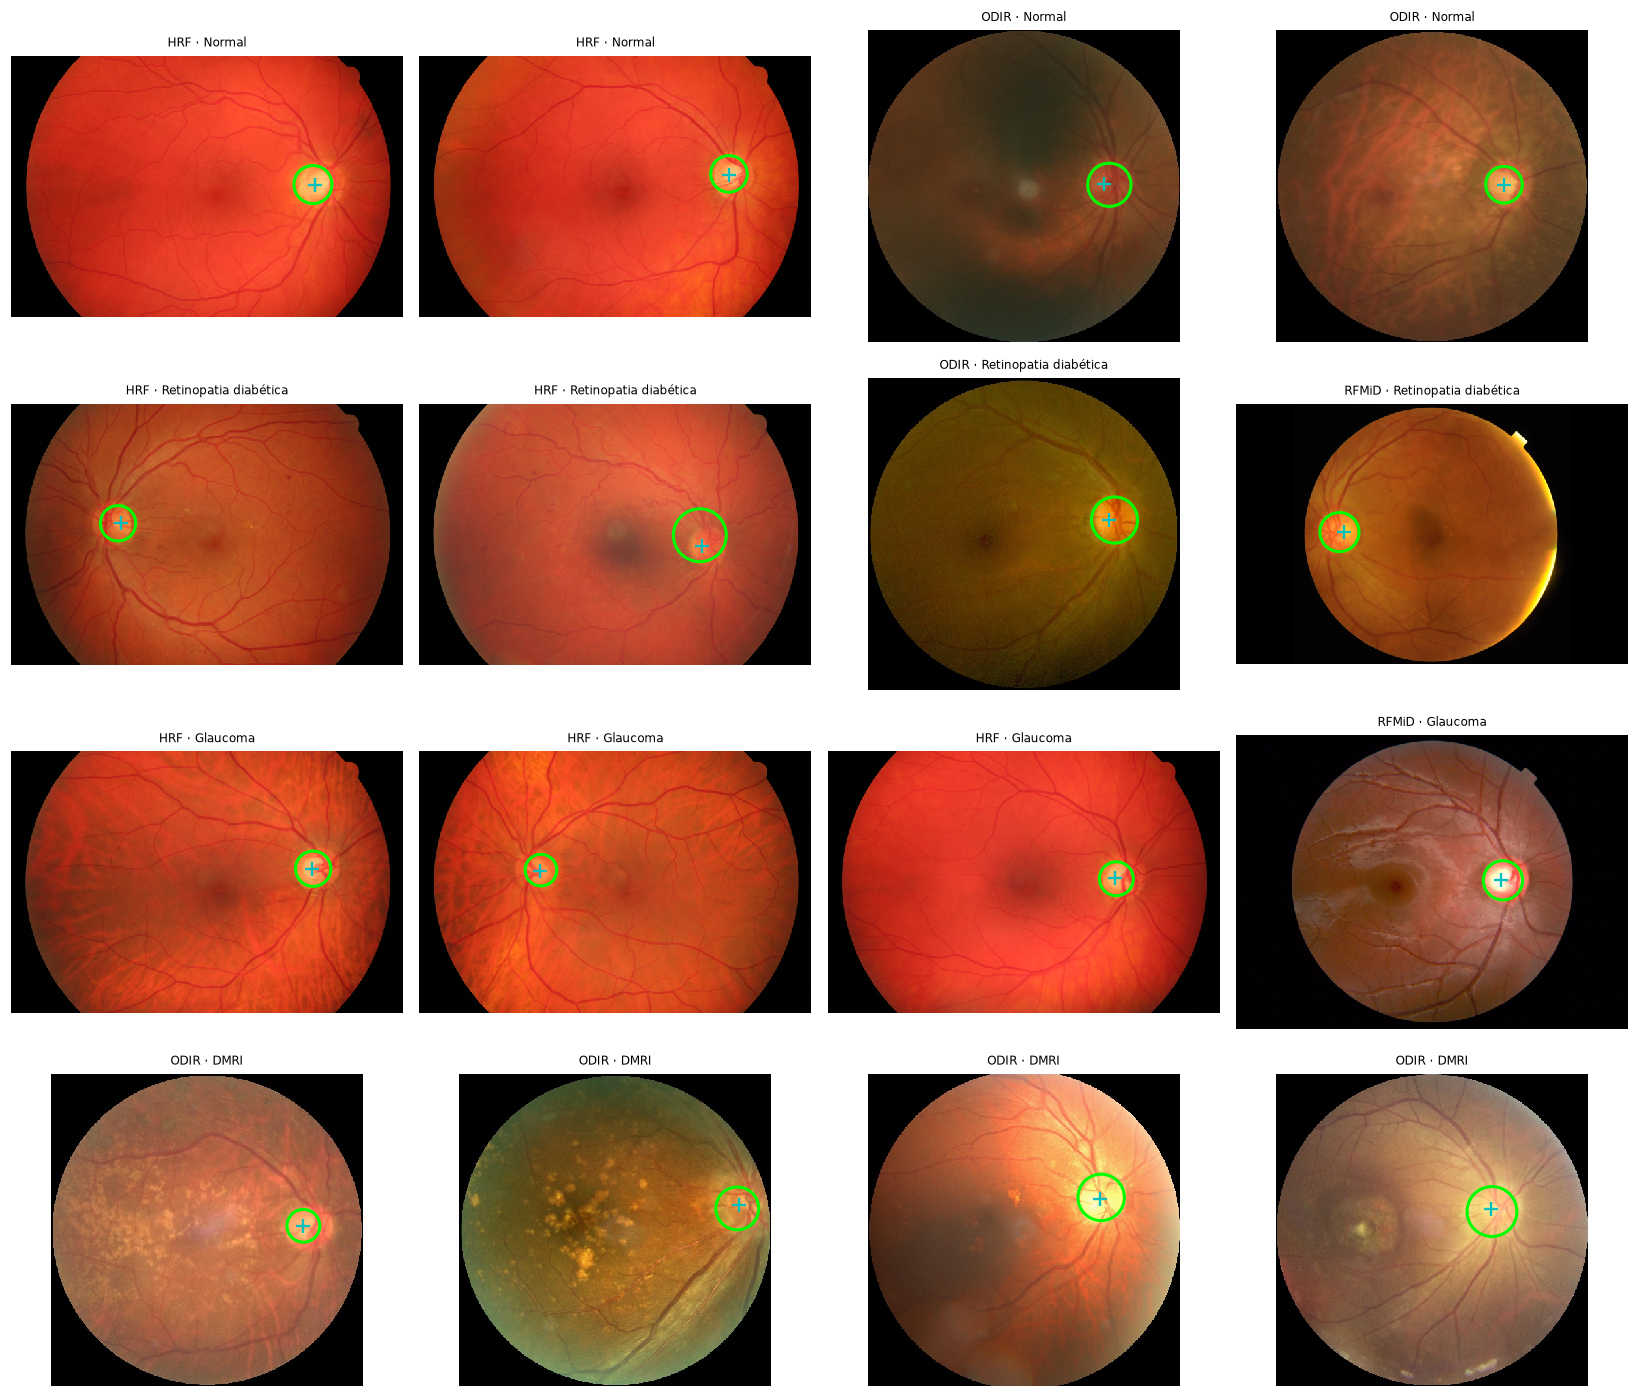

In [11]:
fig, axs = plt.subplots(len(dados.CONDICOES), 4, figsize=(15, 3.2 * len(dados.CONDICOES)))
for i, c in enumerate(dados.CONDICOES):
    for j, (_, r) in enumerate(dados.selecionar(c, n=4, seed=11).iterrows()):
        im = dados.reduzir(dados.carregar_rgb(r.arquivo), 600); d = P.localizar_disco_optico(im)
        ax = axs[i, j]; ax.imshow(im); ax.axis("off"); ax.set_title(f"{r.fonte} · {dados.NOMES_CONDICAO[c]}", fontsize=8)
        ax.plot(d.candidato[1], d.candidato[0], "c+", ms=9, mew=1.5)
        if d.raio: ax.add_patch(plt.Circle((d.centro[1], d.centro[0]), d.raio, fill=False, color="lime", lw=2))
fig.tight_layout(); V.salvar_figura(fig, "04_disco_optico"); plt.show()

**Onde falha.** Exsudatos muito grandes e brilhantes competem com o disco, e reflexos claros na borda do FOV podem ser tomados por ele (`+` ciano = candidato inicial, círculo = disco segmentado):

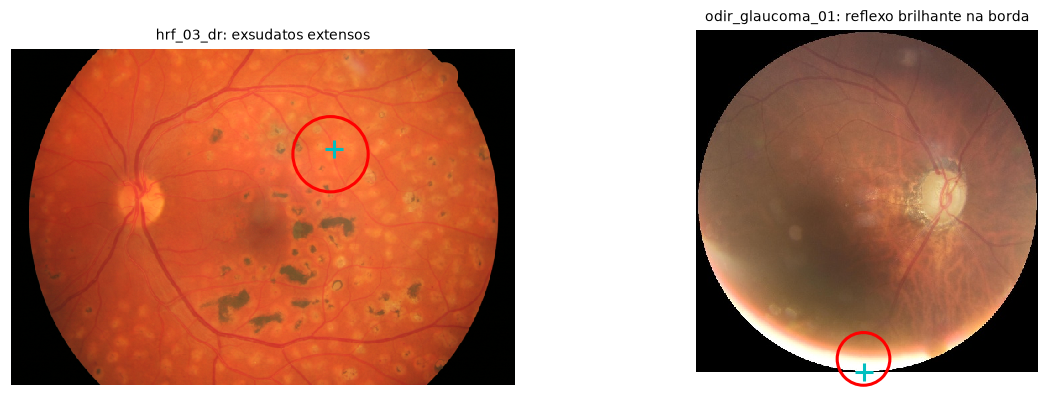

In [12]:
falhas = [("hrf_03_dr", "exsudatos extensos"), ("odir_glaucoma_01", "reflexo brilhante na borda")]
m_ = dados.carregar_manifesto().set_index("id")
fig, axs = plt.subplots(1, len(falhas), figsize=(6.5 * len(falhas), 4.4))
for ax, (id_, motivo) in zip(axs, falhas):
    im = dados.reduzir(dados.carregar_rgb(m_.loc[id_, "arquivo"]), 600); d = P.localizar_disco_optico(im)
    ax.imshow(im); ax.axis("off"); ax.set_title(f"{id_}: {motivo}", fontsize=9); ax.plot(d.candidato[1], d.candidato[0], "c+", ms=12, mew=2)
    if d.raio: ax.add_patch(plt.Circle((d.centro[1], d.centro[0]), d.raio, fill=False, color="red", lw=2))
plt.show()

### E o glaucoma?
O sinal do glaucoma não é o disco em si, mas a **escavação** (o "copo" claro dentro do disco) em relação ao disco — a razão **escavação/disco (CDR)**. Compare o disco de olhos normais com discos rotulados como "escavação" (RFMiD):

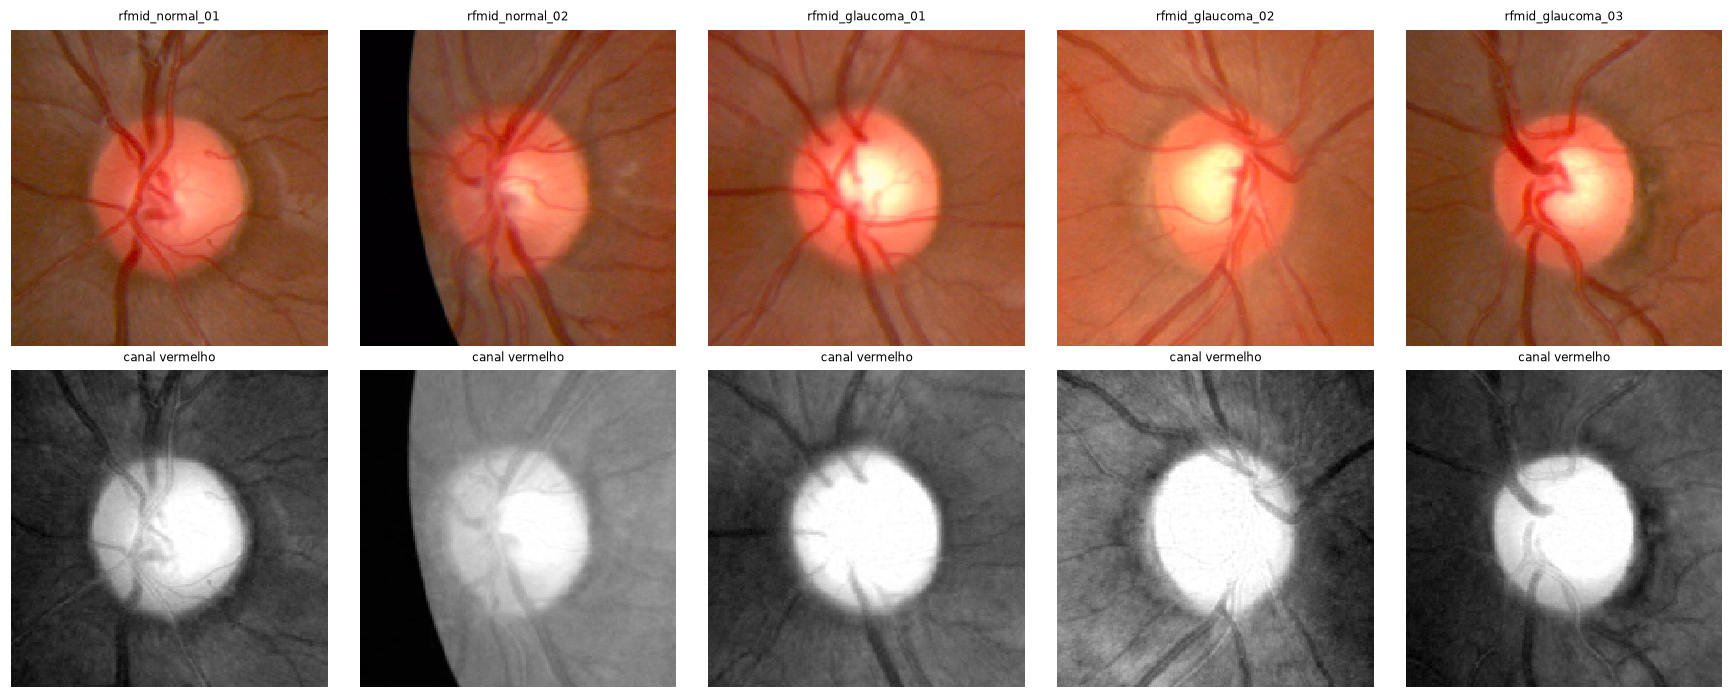

In [13]:
def recorte_disco(id_):
    im = dados.reduzir(dados.carregar_rgb(m_.loc[id_, "arquivo"]), 800); d = P.localizar_disco_optico(im)
    cy, cx = (int(v) for v in d.centro); r = int(2.2 * d.raio)
    return im[max(cy - r, 0):cy + r, max(cx - r, 0):cx + r]

ids = ["rfmid_normal_01", "rfmid_normal_02", "rfmid_glaucoma_01", "rfmid_glaucoma_02", "rfmid_glaucoma_03"]
fig, axs = plt.subplots(2, len(ids), figsize=(3.2 * len(ids), 6.4))
for j, id_ in enumerate(ids):
    rec = recorte_disco(id_)
    axs[0, j].imshow(rec); axs[0, j].set_title(id_, fontsize=8); axs[1, j].imshow(rec[..., 0], cmap="gray"); axs[1, j].set_title("canal vermelho", fontsize=8)
    axs[0, j].axis("off"); axs[1, j].axis("off")
fig.tight_layout(); plt.show()

Medir o CDR exige segmentar **separadamente** o disco e a escavação — fronteiras de baixo contraste, muito variáveis entre pacientes. Métodos clássicos por limiar não são confiáveis aqui; é o tipo de problema para o qual o **REFUGE** e as CNNs do Módulo 4 foram criados.

## 6. Candidatos a lesão (e por que a morfologia simples não basta)

* **Lesões claras** (exsudatos duros da RD, drusas da DMRI): *top-hat* — `I − abertura(I)` realça manchas claras menores que o elemento estruturante.
* **Lesões escuras** (microaneurismas e hemorragias): *black-hat* excluindo os **vasos** segmentados (que também são escuros e finos).

Excluímos o disco óptico (claro por natureza) e a faixa de borda do FOV. **Não há padrão-ouro de lesões** nestas imagens; o objetivo é ver o que uma regra simples "enxerga".

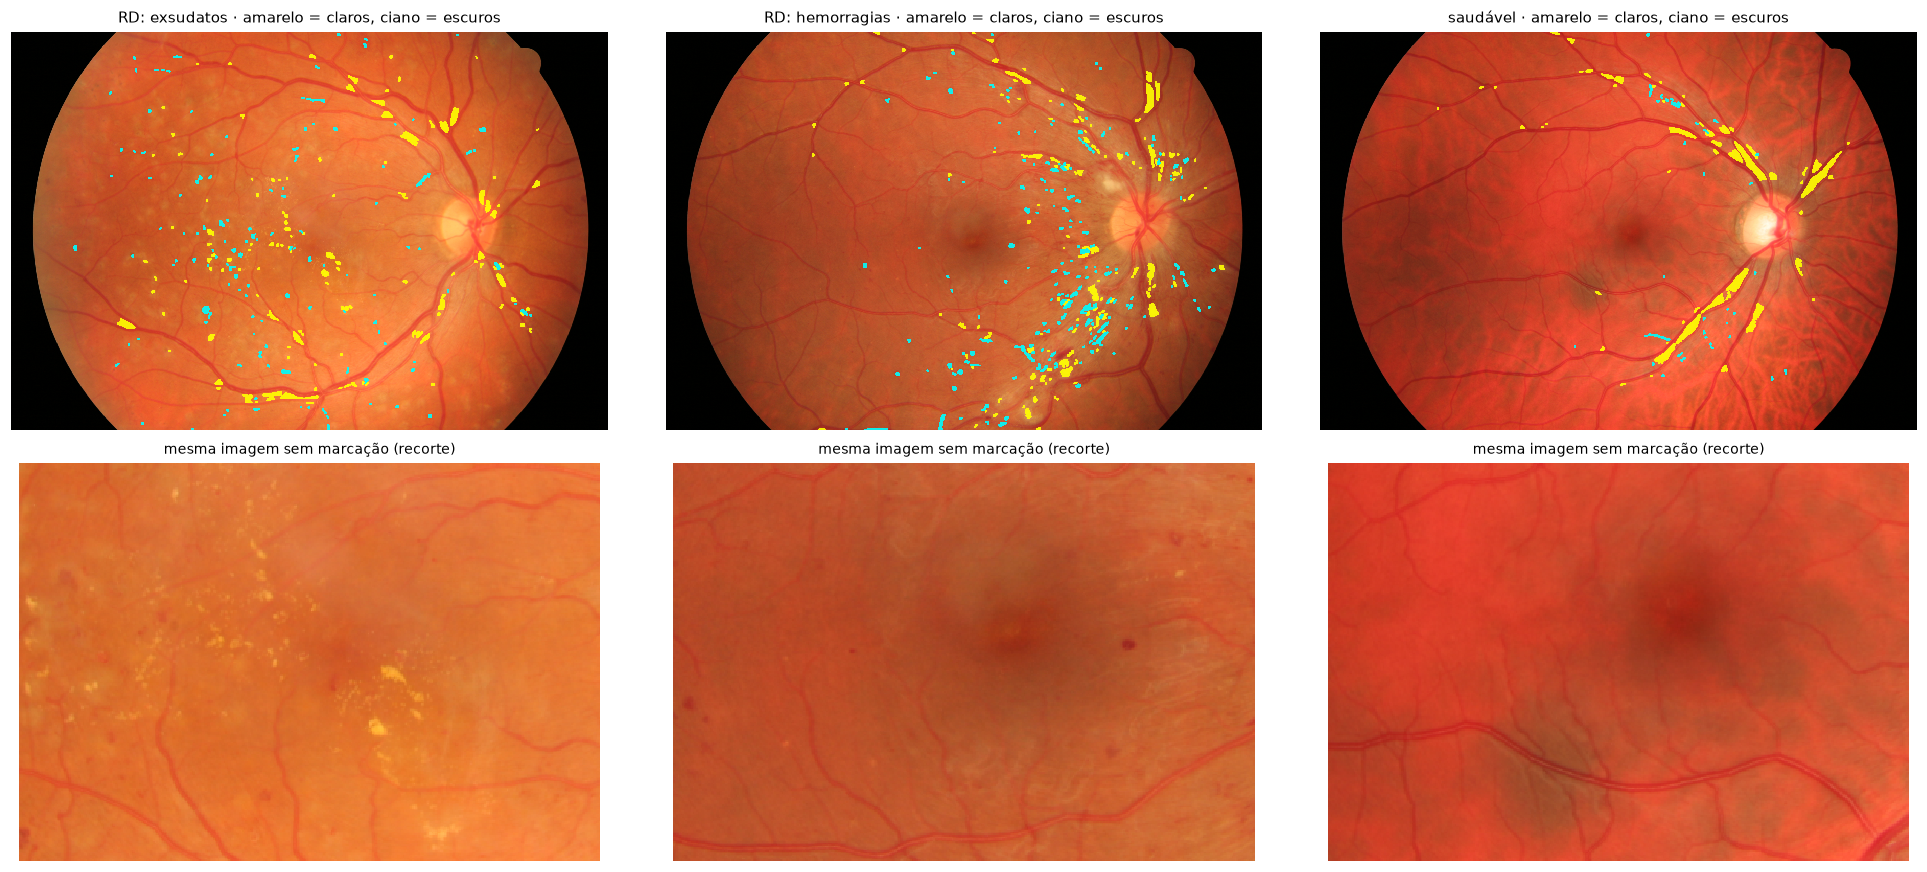

In [14]:
def zona_valida(rgb_, fov_, largura_borda=0.03):
    d = P.localizar_disco_optico(rgb_, fov_); excl = np.zeros_like(fov_)
    if d.mascara is not None:
        excl = cv2.dilate(d.mascara.astype(np.uint8), cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (61, 61))).astype(bool)
    return P.erodir_fov(fov_, int(largura_borda * min(fov_.shape))) & ~excl

def candidatos_claros(rgb_, fov_, k=4.0, r=9):
    g = cv2.GaussianBlur(P.preencher_fora_do_fov(rgb_[..., 1], fov_), (0, 0), 1.0)
    th = cv2.morphologyEx(g, cv2.MORPH_TOPHAT, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * r + 1,) * 2)).astype(np.float32)
    zona = zona_valida(rgb_, fov_)
    lim = max(12.0, th[zona].mean() + k * th[zona].std())
    return P.remover_componentes_pequenos((th > lim) & zona, 6), zona

def candidatos_escuros(rgb_, fov_, vasos_pred, k=4.0, r=7):
    g = cv2.GaussianBlur(P.preencher_fora_do_fov(rgb_[..., 1], fov_), (0, 0), 1.0)
    bh = cv2.morphologyEx(g, cv2.MORPH_BLACKHAT, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * r + 1,) * 2)).astype(np.float32)
    zona = zona_valida(rgb_, fov_) & ~cv2.dilate(vasos_pred.astype(np.uint8), np.ones((7, 7), np.uint8)).astype(bool)
    lim = max(10.0, bh[zona].mean() + k * bh[zona].std())
    return P.remover_componentes_pequenos((bh > lim) & zona, 6), zona

casos = [("hrf_08_dr", "RD: exsudatos"), ("hrf_15_dr", "RD: hemorragias"), ("hrf_01_h", "saudável")]
fig, axs = plt.subplots(2, len(casos), figsize=(6 * len(casos), 8))
for j, (id_, t_) in enumerate(casos):
    it = por_id[id_]; r_, f_ = it["rgb"], it["fov"]
    mc, _ = candidatos_claros(r_, f_); me, _ = candidatos_escuros(r_, f_, P.segmentar_vasos(r_, f_))
    axs[0, j].imshow(V.sobrepor(V.sobrepor(r_, cv2.dilate(mc.astype(np.uint8), np.ones((3, 3), np.uint8)).astype(bool), (255, 255, 0), 0.9),
                                cv2.dilate(me.astype(np.uint8), np.ones((3, 3), np.uint8)).astype(bool), (0, 255, 255), 0.9))
    axs[0, j].set_title(f"{t_} · amarelo = claros, ciano = escuros"); axs[0, j].axis("off")
    axs[1, j].imshow(r_[300:560, 380:760]); axs[1, j].set_title("mesma imagem sem marcação (recorte)", fontsize=9); axs[1, j].axis("off")
fig.tight_layout(); V.salvar_figura(fig, "04_candidatos_lesao"); plt.show()

Agora o teste que importa: **a fração de área sinalizada separa as condições?** Rodamos nas 45 imagens (~ 1–2 min):

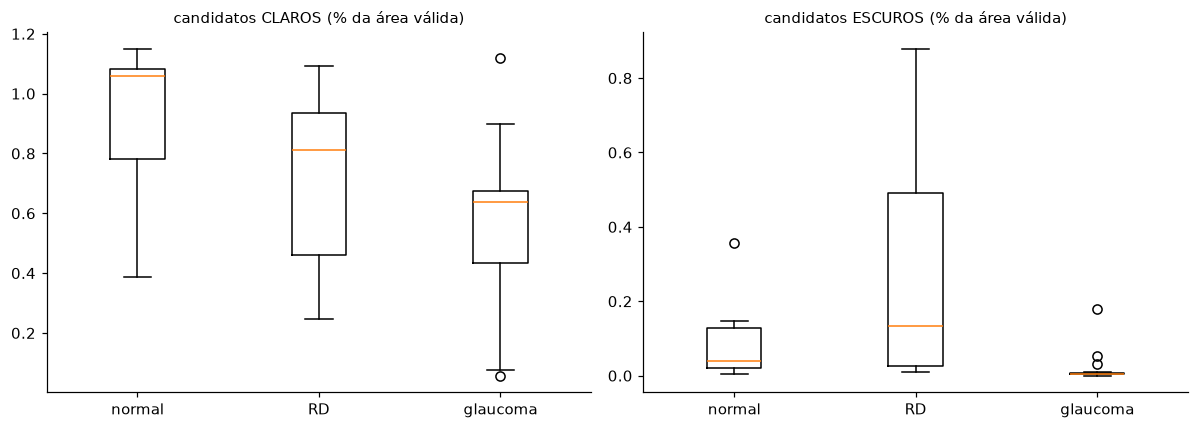

,claros_pct,escuros_pct
condicao,,
glaucoma,0.637,0.006
normal,1.059,0.039
rd,0.813,0.133


In [15]:
linhas = []
for it in hrf:
    r_, f_ = it["rgb"], it["fov"]
    mc, zc = candidatos_claros(r_, f_); me, ze = candidatos_escuros(r_, f_, P.segmentar_vasos(r_, f_))
    linhas.append(dict(condicao=it["meta"].condicao, claros_pct=100 * mc.sum() / zc.sum(), escuros_pct=100 * me.sum() / ze.sum()))
les = pd.DataFrame(linhas)

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, t_ in zip(axs, ["claros_pct", "escuros_pct"], ["candidatos CLAROS (% da área válida)", "candidatos ESCUROS (% da área válida)"]):
    ax.boxplot([les[les.condicao == c][col] for c in ["normal", "rd", "glaucoma"]]); ax.set_xticklabels(["normal", "RD", "glaucoma"]); ax.set_title(t_, fontsize=10)
fig.tight_layout(); plt.show()
les.groupby("condicao").median().round(3)

**O que os números mostram:**

* **Candidatos escuros** aumentam na RD (hemorragias/microaneurismas) em relação a normais e glaucoma — há sinal, mas com **grande dispersão** entre pacientes;
* **Candidatos claros** *não* separam as condições: a retina saudável também tem manchas claras (reflexos, textura da coroide, bordas do disco) que o top-hat não distingue de exsudatos.

Uma regra de morfologia + limiar não conhece **contexto** (forma, localização, textura ao redor). Por isso o Módulo 4 treina CNNs: elas aprendem esse contexto a partir de milhares de exemplos rotulados.
O papel da segmentação clássica no projeto é outro: **localizar o disco, medir a qualidade e dar interpretabilidade** (p. ex. mostrar ao clínico onde estão os vasos).

## Exercícios propostos

1. **Elemento estruturante.** No black-hat, varie o raio do elemento estruturante de 3 a 15 px. Plote o Dice (nas 15 imagens normais) × raio e explique o melhor valor com base na espessura dos vasos.
2. **Limiares da histerese.** Varra `pct_baixo` ∈ {80…92} e `pct_alto` ∈ {93…99} em `P.segmentar_vasos` e faça um mapa de calor do Dice. Existe uma região plana (robusta) ou o resultado é sensível?
3. **Outro canal.** Troque o canal verde pelo **a\*** do LAB (notebook 02: vasos brilhantes) ou combine G e a\*. O Dice melhora na RD?
4. **Esqueletização.** Use `skimage.morphology.skeletonize` na máscara de vasos e estime o **comprimento total** e a **densidade** vascular (px de esqueleto / área). Compare normal × RD.
5. **Razão disco/FOV.** Com `localizar_disco_optico`, calcule a razão diâmetro do disco/diâmetro do FOV nas 115 imagens. Que fonte tem a maior variação? (Relacione com o notebook 01.)
6. **Lesões.** Use limiar por percentil em vez de "média + k·desvio" nos candidatos claros e escuros. O resultado muda? Proponha uma característica adicional (forma? cor em LAB?) que melhore a separação.